In [44]:
import pandas as pd
from src import mislabel_detection, taxonomy

In [45]:
radii = [0.7, 0.5, 0.3, 0.25, 0.2, 0.15, 0.1, 0.05, 0.01]

tax_df = taxonomy.load_tax_qiime('data/cox2_th_final_missing_05_13_02/output/cox2_th-qiime.tsv').rename_axis('seq_id').reset_index()

results = []
result_dfs = {}
for r in radii:
    df = mislabel_detection.validate_at_rank(
        tax_df,
        'data/cox2_th_final_missing_05_13_02/tree/cox2_th-tree-dist.csv',
        k=10,
        max_radius=r,
        min_neighbors=3,
        confidence_threshold=0.7,
        rank_level='genus',
    )
    results.append({
        'max_radius': r,
        'classified': df['predicted_label'].notna().sum(),
        'mislabeled': df['is_mislabeled'].sum(),
    })
    result_dfs[r] = df

results_df = pd.DataFrame(results)
results_df

,max_radius,classified,mislabeled
0,0.70,1321,60
1,0.50,1307,57
2,0.30,1279,47
3,0.25,1254,36
4,0.20,1220,20
5,0.15,1156,15
6,0.10,1032,12
7,0.05,755,4
8,0.01,173,1


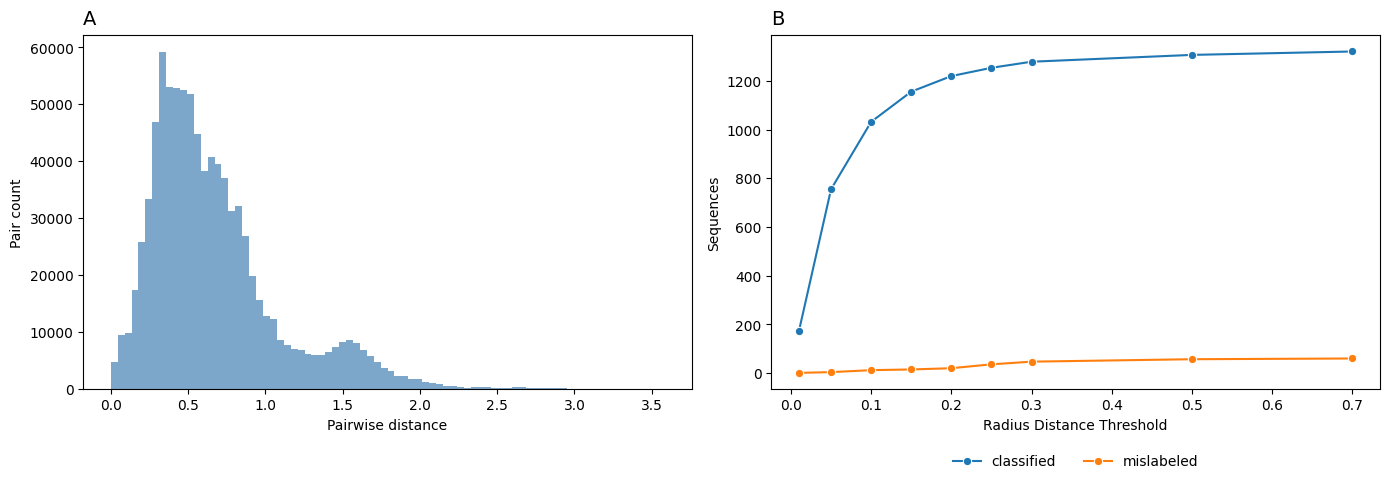

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['svg.fonttype'] = 'none'

dist_path = 'data/cox2_th_final_missing_05_13_02/tree/cox2_th-tree-dist.csv'

upper_triangle = []
with open(dist_path) as f:
    n = int(f.readline())
    for row_idx, line in enumerate(f):
        fields = line.split('\t')
        upper_triangle.extend(map(float, fields[row_idx + 2: n + 1]))

distances = np.array(upper_triangle, dtype=np.float32)

plot_df = results_df.melt(id_vars='max_radius', value_vars=['classified', 'mislabeled'],
                          var_name='metric', value_name='count')

fig, (ax_hist, ax_lines) = plt.subplots(1, 2, figsize=(14, 5))

ax_hist.hist(distances, bins=80, color='steelblue', alpha=0.7)
ax_hist.set_xlabel('Pairwise distance')
ax_hist.set_ylabel('Pair count')
ax_hist.text(0, 1.02, 'A', transform=ax_hist.transAxes, fontsize=14, va='bottom')

sns.lineplot(data=plot_df, x='max_radius', y='count', hue='metric', marker='o', ax=ax_lines)
ax_lines.set_xlabel('Radius Distance Threshold')
ax_lines.set_ylabel('Sequences')
ax_lines.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncols=2, frameon=False)
ax_lines.text(0, 1.02, 'B', transform=ax_lines.transAxes, fontsize=14, va='bottom')

plt.tight_layout()
plt.savefig('radius-analysis.pdf')
plt.show()

In [47]:
df = result_dfs[0.20]
positive: pd.DataFrame = df[df['is_mislabeled'] == True]
positive = positive.sort_values(by='seq_id')
positive

,seq_id,predicted_label,score,is_mislabeled
99,AF086693.1,g__Aphanomyces,1.000,True
123,AF290309.1,g__Pythium,1.000,True
124,AF290310.1,g__Lagenidium,1.000,True
125,AF290311.1,g__Halophytophthora,1.000,True
139,AY286222.1,g__Phytophthora,1.000,True
175,DQ365700.1,g__Phytophthora,1.000,True
208,EF426475.1,g__Phytophthora,1.000,True
259,GU216233.1,g__Bremia,0.900,True
339,HQ721468.1,g__Phytopythium,1.000,True
458,KJ595414.1,g__Globisporangium,1.000,True


In [48]:
from Bio import SeqIO

fasta_path = 'data/cox2_th_final_missing_05_13_02/mislabeled-sequences.fasta'
dist_path  = 'data/cox2_th_final_missing_05_13_02/tree/cox2_th-tree-dist.csv'
out_path   = 'data/cox2_th_final_missing_05_13_02/mislabeled-nearest-neighbors.txt'

query_ids = {rec.id for rec in SeqIO.parse(fasta_path, 'fasta')}

# First pass: collect ordered column IDs
with open(dist_path) as f:
    n = int(f.readline())
    col_ids = np.array([line[:line.index('\t')] for line in f])

query_indices = {sid: idx for idx, sid in enumerate(col_ids) if sid in query_ids}

# Second pass: stream rows that belong to query sequences
neighbors: dict[str, list[str]] = {}
with open(dist_path) as f:
    f.readline()  # skip count
    for row_idx, line in enumerate(f):
        seq_id = col_ids[row_idx]
        if seq_id not in query_ids:
            continue
        distances = np.fromstring(line[line.index('\t') + 1:], dtype=np.float32, sep='\t')
        distances[row_idx] = np.inf  # exclude self
        top10_idx = np.argsort(distances)[:10]
        neighbors[seq_id] = col_ids[top10_idx].tolist()

# Collect unique neighbor accessions (excluding the query sequences themselves)
all_neighbors = {acc for accs in neighbors.values() for acc in accs} - query_ids

with open(out_path, 'w') as f:
    for acc in sorted(all_neighbors):
        f.write(acc + '\n')

print(f"Wrote {len(all_neighbors)} unique neighbor accessions to {out_path}")
neighbors

Wrote 119 unique neighbor accessions to data/cox2_th_final_missing_05_13_02/mislabeled-nearest-neighbors.txt


{np.str_('AF086693.1'): ['LC730889.1',
  'LC730888.1',
  'AF086692.1',
  'LC730891.1',
  'LC730897.1',
  'LC730893.1',
  'LC730895.1',
  'PQ228186.1',
  'LC730892.1',
  'KJ654177.1'],
 np.str_('AF290309.1'): ['OQ291216.1',
  'KJ595363.1',
  'MG813944.1',
  'KJ595394.1',
  'KJ595398.1',
  'KJ595359.1',
  'DQ082849.1',
  'PQ349318.1',
  'DQ365765.1',
  'OR484957.1'],
 np.str_('AF290310.1'): ['MK490904.1',
  'KJ506083.1',
  'MK490907.1',
  'KJ506087.1',
  'KC741467.1',
  'AF086697.1',
  'KT257437.1',
  'KX389265.1',
  'HQ660436.1',
  'JX970838.1'],
 np.str_('AF290311.1'): ['DQ365703.1',
  'OQ605397.1',
  'OQ605400.1',
  'MF991426.1',
  'MF991427.1',
  'OQ605401.1',
  'OQ605403.1',
  'OQ605402.1',
  'OQ605398.1',
  'OQ605399.1'],
 np.str_('HQ721468.1'): ['MK425691.1',
  'AB690672.1',
  'OR704577.1',
  'OR239414.1',
  'MG813930.1',
  'MW208003.1',
  'KJ595436.1',
  'AB690665.1',
  'AB690679.1',
  'MT720676.1'],
 np.str_('KJ595414.1'): ['GU071764.1',
  'AB512875.1',
  'AB512874.1',
  'PX5054